In [1]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/vietnamese-summarization")

for folder_name in ["data", "checkpoints", "outputs"]:
    folder_path = drive_root / folder_name

    if not folder_path.is_dir():
        raise RuntimeError(f"Lỗi: Chưa có thư mục Drive: {folder_path}")

print("Đã kết nối Drive và tìm thấy đủ thư mục dự án.")

Mounted at /content/drive
Đã kết nối Drive và tìm thấy đủ thư mục dự án.


In [2]:
import os
import sys
import subprocess
from pathlib import Path

repo_url = "https://github.com/MD1809/vietnamese-summarization.git"
repo_dir = Path("/content/vietnamese-summarization")
target_commit = "5cf7db98d3823ef2beb3368c9d0accc283e64c68"

if not repo_dir.exists():
    subprocess.run(
        ["git", "clone", repo_url, str(repo_dir)],
        check=True,
    )

remote_result = subprocess.run(
    ["git", "remote", "get-url", "origin"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

if remote_result.stdout.strip() != repo_url:
    raise RuntimeError("Lỗi: Repository không đúng dự án.")

status_result = subprocess.run(
    ["git", "status", "--porcelain"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

if status_result.stdout.strip() != "":
    raise RuntimeError("Lỗi: Repository còn thay đổi. Hãy dùng runtime mới.")

subprocess.run(
    ["git", "fetch", "origin"],
    cwd=repo_dir,
    check=True,
)

subprocess.run(
    ["git", "checkout", "--detach", target_commit],
    cwd=repo_dir,
    check=True,
)

commit_result = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

git_commit = commit_result.stdout.strip()

os.chdir(repo_dir)

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

print("Commit nền:", git_commit)
print("Thư mục làm việc:", Path.cwd())

Commit nền: 5cf7db98d3823ef2beb3368c9d0accc283e64c68
Thư mục làm việc: /content/vietnamese-summarization


In [3]:
%pip uninstall -y diffusers torchvision timm fastai
%pip install "jedi==0.20.1"
%pip install -r /content/vietnamese-summarization/requirements.txt
%pip check

Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1
Found existing installation: torchvision 0.29.1+cu130
Uninstalling torchvision-0.29.1+cu130:
  Successfully uninstalled torchvision-0.29.1+cu130
Found existing installation: timm 1.0.31
Uninstalling timm-1.0.31:
  Successfully uninstalled timm-1.0.31
Found existing installation: fastai 2.8.12
Uninstalling fastai-2.8.12:
  Successfully uninstalled fastai-2.8.12
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 19.3 MB/s  0:00:00
Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu130
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 147.7 MB/s  0:00:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 193.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 

In [4]:
import importlib
import json
import platform
from importlib.metadata import version

packages = {
    "torch": "torch",
    "transformers": "transformers",
    "datasets": "datasets",
    "sentencepiece": "sentencepiece",
    "rouge-score": "rouge_score",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "gradio": "gradio",
    "numpy": "numpy",
}

library_versions = {}

for package_name in packages:
    module_name = packages[package_name]
    importlib.import_module(module_name)
    library_versions[package_name] = version(package_name)

result = {
    "python_version": platform.python_version(),
    "library_versions": library_versions,
    "import_check_passed": True,
}

print(json.dumps(result, ensure_ascii=False, indent=2))

{
  "python_version": "3.13.16",
  "library_versions": {
    "torch": "2.11.0+cu130",
    "transformers": "4.57.6",
    "datasets": "4.8.5",
    "sentencepiece": "0.2.2",
    "rouge-score": "0.1.2",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "gradio": "6.17.3",
    "numpy": "2.4.6"
  },
  "import_check_passed": true
}


In [5]:
import json
import platform
import torch
from datetime import datetime, timezone

environment = {
    "run_id": "colab_environment_check",
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "pytorch_version": str(torch.__version__),
    "pytorch_cuda_version": torch.version.cuda,
    "cuda_available": torch.cuda.is_available(),
    "gpus": [],
    "gpu_check_passed": False,
    "diagnostics": [],
}

if environment["cuda_available"]:
    for index in range(torch.cuda.device_count()):
        gpu = torch.cuda.get_device_properties(index)

        gpu_info = {
            "index": index,
            "name": gpu.name,
            "total_vram_gib": round(gpu.total_memory / 1024**3, 2),
        }

        environment["gpus"].append(gpu_info)

    if len(environment["gpus"]) > 0:
        environment["gpu_check_passed"] = True
else:
    environment["diagnostics"].append(
        "Chưa truy cập được GPU. Hãy kiểm tra loại runtime."
    )

print(json.dumps(environment, ensure_ascii=False, indent=2))

if not environment["gpu_check_passed"]:
    raise RuntimeError("Lỗi: Kiểm tra môi trường GPU chưa đạt.")

{
  "run_id": "colab_environment_check",
  "checked_at_utc": "2026-11-08T18:31:35.570638+00:00",
  "python_version": "3.13.16",
  "pytorch_version": "2.11.0+cu130",
  "pytorch_cuda_version": "13.0",
  "cuda_available": true,
  "gpus": [
    {
      "index": 0,
      "name": "Tesla T4",
      "total_vram_gib": 14.56
    }
  ],
  "gpu_check_passed": true,
  "diagnostics": []
}


In [6]:
import json

if "environment" not in globals():
    raise RuntimeError("Lỗi: Chưa có dữ liệu môi trường.")

if "drive_root" not in globals():
    raise RuntimeError("Lỗi: Chưa kết nối Drive.")

if "git_commit" not in globals():
    raise RuntimeError("Lỗi: Chưa xác định commit đang sử dụng.")

if "library_versions" not in globals():
    raise RuntimeError("Lỗi: Chưa kiểm tra phiên bản thư viện.")

environment["git_commit"] = git_commit
environment["library_versions"] = library_versions

report_path = drive_root / "outputs" / environment["run_id"] / "config.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(
    json.dumps(environment, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Đã lưu hồ sơ trực tiếp trên Drive:", report_path)

Đã lưu hồ sơ trực tiếp trên Drive: /content/drive/MyDrive/vietnamese-summarization/outputs/colab_environment_check/config.json


In [ ]:
import importlib
from google.colab import files

source_paths = [
    "configs/train.json",
    "src/data.py",
    "src/tokenization.py",
    "src/train.py",
]

for relative_path in source_paths:
    print("Chọn file:", relative_path)
    uploaded = files.upload()

    if len(uploaded) != 1:
        raise RuntimeError("Lỗi: Mỗi lượt chỉ chọn đúng một file.")

    for file_name in uploaded:
        uploaded_content = uploaded[file_name]

    target_path = repo_dir / relative_path
    target_path.parent.mkdir(parents=True, exist_ok=True)
    target_path.write_bytes(uploaded_content)

    print("Đã cập nhật:", target_path)

import src.data
import src.tokenization
import src.train

importlib.reload(src.data)
importlib.reload(src.tokenization)
importlib.reload(src.train)

In [ ]:
import json
from src.utils import load_train_config, set_seed

train_config = load_train_config()
set_seed(train_config["seed"])

tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
)

data_loaders = src.tokenization.create_train_validation_loaders(
    tokenized_splits,
    tokenizer,
)

forward_batch = next(iter(data_loaders["train"]))

batch_shapes = {}

for field in ["input_ids", "attention_mask", "labels"]:
    batch_shapes[field] = list(forward_batch["model_inputs"][field].shape)

print(json.dumps(
    {
        "sample_ids": forward_batch["sample_ids"],
        "batch_size": train_config["batch_size"],
        "shapes": batch_shapes,
    },
    ensure_ascii=False,
    indent=2,
))

In [ ]:
model = src.train.load_vit5_model()

forward_report = src.train.check_forward_batch(
    model,
    forward_batch,
)

forward_report["model_id"] = train_config["model"]["id"]
forward_report["model_revision"] = train_config["model"]["revision"]
forward_report["max_source_length"] = train_config["max_source_length"]
forward_report["max_target_length"] = train_config["max_target_length"]
forward_report["task_prefix"] = train_config["task_prefix"]
forward_report["source_mode"] = "local files uploaded for pre-commit check"
forward_report["test_content_read"] = False

print(json.dumps(
    forward_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import importlib
from google.colab import files

uploaded = files.upload()

if len(uploaded) != 1:
    raise RuntimeError("Lỗi: Hãy chọn đúng một file src/train.py.")

for file_name in uploaded:
    uploaded_content = uploaded[file_name]

target_path = repo_dir / "src" / "train.py"
target_path.write_bytes(uploaded_content)

import src.train

importlib.reload(src.train)

print("Đã cập nhật src/train.py trong runtime.")

In [ ]:
import json

optimizer = src.train.create_optimizer(model)

optimization_report = src.train.check_optimization_step(
    model,
    forward_batch,
    optimizer,
)

optimization_report["model_id"] = train_config["model"]["id"]
optimization_report["model_revision"] = train_config["model"]["revision"]
optimization_report["max_source_length"] = train_config["max_source_length"]
optimization_report["max_target_length"] = train_config["max_target_length"]
optimization_report["learning_rate"] = train_config["learning_rate"]
optimization_report["weight_decay"] = train_config["weight_decay"]
optimization_report["source_mode"] = "local files uploaded for pre-commit check"

print(json.dumps(
    optimization_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import torch
from src.utils import set_seed

small_sample_batches = src.train.create_small_sample_batches(
    tokenized_splits["train"],
    tokenizer,
    seed=train_config["seed"],
)

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

model = src.train.load_vit5_model()
optimizer = src.train.create_optimizer(model)

print("Đã chuẩn bị 16 mẫu train cố định.")
print("Đã tải lại ViT5-Base và tạo optimizer mới.")

In [ ]:
import json

small_sample_report = src.train.run_small_sample_check(
    model,
    small_sample_batches,
    optimizer,
)

small_sample_report["model_id"] = train_config["model"]["id"]
small_sample_report["model_revision"] = train_config["model"]["revision"]
small_sample_report["seed"] = train_config["seed"]
small_sample_report["precision"] = train_config["precision"]
small_sample_report["max_source_length"] = train_config["max_source_length"]
small_sample_report["max_target_length"] = train_config["max_target_length"]
small_sample_report["learning_rate"] = train_config["learning_rate"]
small_sample_report["weight_decay"] = train_config["weight_decay"]
small_sample_report["initialization"] = "fresh pretrained model and optimizer"
small_sample_report["source_mode"] = "local files uploaded for pre-commit check"

print(json.dumps(
    small_sample_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
model_origin = "existing runtime model"

if "model" not in globals():
    model = src.train.load_vit5_model()
    model_origin = "fresh pretrained ViT5-Base"

print("Điểm khởi đầu:", model_origin)
print("Số mẫu validation:", len(tokenized_splits["validation"]))

In [ ]:
import json

expected_validation_ids = []

for sample in tokenized_splits["validation"]:
    expected_validation_ids.append(sample["id"])

validation_report = src.train.validate_model(
    model,
    data_loaders["validation"],
    expected_validation_ids,
)

validation_report["model_origin"] = model_origin
validation_report["model_id"] = train_config["model"]["id"]
validation_report["model_revision"] = train_config["model"]["revision"]
validation_report["precision"] = train_config["precision"]
validation_report["batch_size"] = train_config["batch_size"]
validation_report["max_source_length"] = train_config["max_source_length"]
validation_report["max_target_length"] = train_config["max_target_length"]
validation_report["source_mode"] = "local files uploaded for pre-commit check"

print(json.dumps(
    validation_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import torch
from datetime import datetime, timezone
from src.utils import set_seed

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

model = src.train.load_vit5_model()
optimizer = src.train.create_optimizer(model)

checkpoint_batch = forward_batch

probe_text = tokenizer.decode(
    checkpoint_batch["model_inputs"]["input_ids"][0].tolist(),
    skip_special_tokens=True,
)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
run_id = "checkpoint_roundtrip_check_" + timestamp
checkpoint_dir = drive_root / "checkpoints" / run_id / "last"

print("Checkpoint sẽ lưu tại:", checkpoint_dir)
print("Mẫu train:", checkpoint_batch["sample_ids"])

In [ ]:
first_step_report = src.train.check_optimization_step(
    model,
    checkpoint_batch,
    optimizer,
)

probe_before = src.train.generate_checkpoint_probe(
    model,
    tokenizer,
    probe_text,
)

checkpoint_progress = {
    "completed_epochs": 0,
    "global_step": 1,
}

src.train.save_training_checkpoint(
    model,
    tokenizer,
    optimizer,
    checkpoint_dir,
    checkpoint_progress,
)

print("Đã lưu model, tokenizer, optimizer, tiến độ và trạng thái ngẫu nhiên.")
print("Tiến độ đã lưu:", checkpoint_progress)

In [ ]:
del optimizer
del model

gc.collect()
torch.cuda.empty_cache()

model, tokenizer, optimizer, progress, restoration_report = (
    src.train.load_training_checkpoint(checkpoint_dir)
)

print(json.dumps(
    restoration_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
probe_after = src.train.generate_checkpoint_probe(
    model,
    tokenizer,
    probe_text,
)

for field in ["input_ids", "attention_mask", "generated_ids", "generated_text"]:
    if probe_before[field] != probe_after[field]:
        raise RuntimeError("Lỗi: Kết quả sau tải lại không khớp: " + field)

if progress != checkpoint_progress:
    raise RuntimeError("Lỗi: Tiến độ phục hồi không khớp.")

if restoration_report["optimizer_step_values"] != [1]:
    raise RuntimeError("Lỗi: Optimizer chưa phục hồi đúng bước 1.")

resumed_step_report = src.train.check_optimization_step(
    model,
    checkpoint_batch,
    optimizer,
)

progress["global_step"] = progress["global_step"] + 1

optimizer_step_values = set()

for parameter_state in optimizer.state.values():
    step_value = int(parameter_state["step"].item())
    optimizer_step_values.add(step_value)

if optimizer_step_values != {2} or progress["global_step"] != 2:
    raise RuntimeError("Lỗi: Tiến độ sau bước học tiếp chưa đúng.")

checkpoint_files = []

for file_path in checkpoint_dir.iterdir():
    if file_path.is_file():
        checkpoint_files.append(file_path.name)

checkpoint_report = {
    "run_id": run_id,
    "checkpoint_dir": str(checkpoint_dir),
    "checkpoint_files": sorted(checkpoint_files),
    "sample_ids": checkpoint_batch["sample_ids"],
    "model_id": train_config["model"]["id"],
    "model_revision": train_config["model"]["revision"],
    "restoration": restoration_report,
    "tokenizer_check_passed": True,
    "generated_ids_check_passed": True,
    "generated_text_check_passed": True,
    "source_token_count": len(probe_before["input_ids"]),
    "generated_ids_before": probe_before["generated_ids"],
    "generated_ids_after": probe_after["generated_ids"],
    "generated_text": probe_after["generated_text"],
    "generation_config": probe_after["generation_config"],
    "saved_progress": checkpoint_progress,
    "progress_after_resumed_step": progress,
    "optimizer_step_values_after_resume": sorted(optimizer_step_values),
    "first_step": first_step_report,
    "resumed_step": resumed_step_report,
    "test_content_read": False,
    "source_mode": "local files uploaded for pre-commit check",
}

print(json.dumps(
    checkpoint_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import os
import importlib
from google.colab import files

source_paths = [
    "configs/train.json",
    "src/train.py",
]

for relative_path in source_paths:
    print("Chọn file:", relative_path)

    os.chdir("/content")

    try:
        uploaded = files.upload()
    finally:
        os.chdir(repo_dir)

    if len(uploaded) != 1:
        raise RuntimeError("Lỗi: Mỗi lượt chỉ chọn đúng một file.")

    for file_name in uploaded:
        uploaded_content = uploaded[file_name]

    target_path = repo_dir / relative_path
    target_path.write_bytes(uploaded_content)

    print("Đã cập nhật:", relative_path)

import src.train

importlib.reload(src.train)

In [ ]:
import json
import src.train

run_profile = src.train.create_training_run(
    repo_dir,
    drive_root,
    allow_uncommitted=False,
)

profile_path = (
    Path(run_profile["paths"]["output_dir"]) / "config.json"
)

print("Đã lưu và đọc lại hồ sơ thành công:", profile_path)

print(json.dumps(
    run_profile,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import torch
import src.tokenization
from src.utils import load_train_config, set_seed

train_config = load_train_config()

tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
)

resource_batches = src.train.create_small_sample_batches(
    tokenized_splits["train"],
    tokenizer,
    seed=train_config["seed"],
)

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

model = src.train.load_vit5_model()
optimizer = src.train.create_optimizer(model)

print("Đã chuẩn bị 16 mẫu train, ViT5-Base và AdamW mới.")

In [ ]:
import json
from pathlib import Path

resource_report = src.train.run_resource_check(
    model,
    resource_batches,
    optimizer,
    tokenizer,
)

resource_report["run_id"] = run_profile["run_id"]
resource_report["model_id"] = train_config["model"]["id"]
resource_report["model_revision"] = train_config["model"]["revision"]
resource_report["train_sample_count"] = len(tokenized_splits["train"])
resource_report["run_config_file"] = str(
    Path(run_profile["paths"]["output_dir"]) / "config.json"
)

report_path = (
    Path(run_profile["paths"]["output_dir"]) / "resource_check.json"
)

report_path.write_text(
    json.dumps(resource_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

saved_report = json.loads(report_path.read_text(encoding="utf-8"))

if saved_report != resource_report:
    raise RuntimeError("Lỗi: Báo cáo đọc lại không khớp.")

print("Đã lưu và đọc lại báo cáo:", report_path)

print(json.dumps(
    resource_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import torch
import src.tokenization
from src.utils import load_train_config, set_seed

train_config = load_train_config()

tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
)

accumulation_batches = src.train.create_small_sample_batches(
    tokenized_splits["train"],
    tokenizer,
    seed=train_config["seed"],
    sample_count=17,
)

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

model = src.train.load_vit5_model()
optimizer = src.train.create_optimizer(model)

print("Đã chuẩn bị 17 mẫu train và mô hình mới.")
print("Accumulation:", train_config["gradient_accumulation_steps"])
print("Ngưỡng clipping:", train_config["max_grad_norm"])

In [ ]:
import json
from pathlib import Path

accumulation_report = src.train.run_accumulation_check(
    model,
    accumulation_batches,
    optimizer,
)

accumulation_report["run_id"] = run_profile["run_id"]
accumulation_report["model_id"] = train_config["model"]["id"]
accumulation_report["model_revision"] = train_config["model"]["revision"]
accumulation_report["max_source_length"] = train_config["max_source_length"]
accumulation_report["max_target_length"] = train_config["max_target_length"]
accumulation_report["run_config_file"] = str(
    Path(run_profile["paths"]["output_dir"]) / "config.json"
)

report_path = (
    Path(run_profile["paths"]["output_dir"])
    / "gradient_accumulation_check.json"
)

report_path.write_text(
    json.dumps(accumulation_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

saved_report = json.loads(report_path.read_text(encoding="utf-8"))

if saved_report != accumulation_report:
    raise RuntimeError("Lỗi: Báo cáo đọc lại không khớp.")

print("Đã lưu và đọc lại báo cáo:", report_path)

print(json.dumps(
    accumulation_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import random
import torch
import src.tokenization
from pathlib import Path
from src.utils import load_train_config, set_seed

train_config = load_train_config()

tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
)

random_generator = random.Random(train_config["seed"])

selected_indices = random_generator.sample(
    range(len(tokenized_splits["train"])),
    17,
)

checkpoint_test_dataset = tokenized_splits["train"].select(selected_indices)

test_loader = src.tokenization.create_data_loader(
    checkpoint_test_dataset,
    tokenizer,
    batch_size=1,
    shuffle=True,
    seed=train_config["seed"],
)

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

model = src.train.load_vit5_model()
optimizer = src.train.create_optimizer(model)

progress = {
    "completed_epochs": 0,
    "global_step": 0,
}

checkpoint_run_dir = Path(run_profile["paths"]["checkpoint_dir"])

print("Đã chuẩn bị lượt kiểm tra trên 17 mẫu train.")
print("Thư mục checkpoint:", checkpoint_run_dir)

In [ ]:
progress, first_epoch_report = src.train.train_checkpoint_test_epoch(
    model,
    test_loader,
    optimizer,
    progress,
)

first_save_report = src.train.save_last_checkpoint(
    model,
    tokenizer,
    optimizer,
    checkpoint_run_dir,
    progress,
    test_loader,
)

expected_next_epoch_ids = src.train.preview_train_epoch_ids(test_loader)

print("Tiến độ sau epoch thử đầu:", progress)

print(json.dumps(
    first_save_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
del optimizer
del model

gc.collect()
torch.cuda.empty_cache()

test_loader = src.tokenization.create_data_loader(
    checkpoint_test_dataset,
    tokenizer,
    batch_size=1,
    shuffle=True,
    seed=train_config["seed"],
)

model, tokenizer, optimizer, progress, resume_report = (
    src.train.load_last_checkpoint(
        checkpoint_run_dir,
        test_loader,
    )
)

resumed_next_epoch_ids = src.train.preview_train_epoch_ids(test_loader)

if resumed_next_epoch_ids != expected_next_epoch_ids:
    raise RuntimeError("Lỗi: Thứ tự shuffle sau phục hồi không khớp.")

if progress != {"completed_epochs": 1, "global_step": 3}:
    raise RuntimeError("Lỗi: Tiến độ sau phục hồi không đúng.")

print("Thứ tự shuffle sau phục hồi khớp.")

print(json.dumps(
    resume_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
progress, second_epoch_report = src.train.train_checkpoint_test_epoch(
    model,
    test_loader,
    optimizer,
    progress,
)

if progress != {"completed_epochs": 2, "global_step": 6}:
    raise RuntimeError("Lỗi: Tiến độ sau epoch thử thứ hai không đúng.")

second_save_report = src.train.save_last_checkpoint(
    model,
    tokenizer,
    optimizer,
    checkpoint_run_dir,
    progress,
    test_loader,
)

epoch_checkpoint_report = {
    "run_id": run_profile["run_id"],
    "scope": "two test epochs on 17 train samples",
    "resume_boundary": "end_of_epoch",
    "first_epoch": first_epoch_report,
    "first_save": first_save_report,
    "restoration": resume_report,
    "expected_next_epoch_ids": expected_next_epoch_ids,
    "resumed_next_epoch_ids": resumed_next_epoch_ids,
    "next_epoch_order_check_passed": True,
    "second_epoch": second_epoch_report,
    "second_save": second_save_report,
    "final_progress": progress,
    "test_content_read": False,
}

report_path = (
    Path(run_profile["paths"]["output_dir"])
    / "epoch_checkpoint_check.json"
)

report_path.write_text(
    json.dumps(epoch_checkpoint_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

saved_report = json.loads(report_path.read_text(encoding="utf-8"))

if saved_report != epoch_checkpoint_report:
    raise RuntimeError("Lỗi: Báo cáo đọc lại không khớp.")

print("Đã lưu và đọc lại báo cáo:", report_path)

print(json.dumps(
    epoch_checkpoint_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import random
import torch
import src.tokenization
from pathlib import Path
from src.utils import load_train_config, set_seed

train_config = load_train_config()

tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
)

random_generator = random.Random(train_config["seed"])
selected_indices = random_generator.sample(
    range(len(tokenized_splits["train"])),
    17,
)

best_test_dataset = tokenized_splits["train"].select(selected_indices)

best_train_loader = src.tokenization.create_data_loader(
    best_test_dataset,
    tokenizer,
    batch_size=1,
    shuffle=True,
    seed=train_config["seed"],
)

validation_loader = src.tokenization.create_data_loader(
    tokenized_splits["validation"],
    tokenizer,
    batch_size=1,
    shuffle=False,
    seed=train_config["seed"],
)

expected_validation_ids = []

for sample in tokenized_splits["validation"]:
    expected_validation_ids.append(sample["id"])

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

model = src.train.load_vit5_model()
optimizer = src.train.create_optimizer(model)

progress = {"completed_epochs": 0, "global_step": 0}
checkpoint_run_dir = Path(run_profile["paths"]["checkpoint_dir"])

print("Đã chuẩn bị 17 mẫu train và 201 mẫu validation.")

In [ ]:
import json

trials = []
validation_reports = []

for epoch_index in range(2):
    progress, training_report = src.train.train_checkpoint_test_epoch(
        model,
        best_train_loader,
        optimizer,
        progress,
    )

    validation_report = src.train.validate_model(
        model,
        validation_loader,
        expected_validation_ids,
    )

    progress, best_decision = src.train.update_best_checkpoint(
        model,
        tokenizer,
        checkpoint_run_dir,
        progress,
        validation_report,
    )

    last_save = src.train.save_last_checkpoint(
        model,
        tokenizer,
        optimizer,
        checkpoint_run_dir,
        progress,
        best_train_loader,
    )

    trials.append({
        "training": training_report,
        "validation_loss": validation_report["validation_loss"],
        "validation_sample_count": validation_report["sample_count"],
        "best_decision": best_decision,
        "last_save": last_save,
    })

    validation_reports.append(validation_report)

    print(
        "Epoch thử:", progress["completed_epochs"],
        "Validation loss:", validation_report["validation_loss"],
        "Cập nhật best:", best_decision["updated"],
    )

selected_validation_report = validation_reports[progress["best_epoch"] - 1]

selection_path = checkpoint_run_dir / "best" / "selection.json"
metadata_before = selection_path.read_bytes()

progress, equal_loss_decision = src.train.update_best_checkpoint(
    model,
    tokenizer,
    checkpoint_run_dir,
    progress,
    selected_validation_report,
)

if equal_loss_decision["updated"]:
    raise RuntimeError("Lỗi: Loss bằng nhau nhưng best bị cập nhật.")

if selection_path.read_bytes() != metadata_before:
    raise RuntimeError("Lỗi: Metadata best thay đổi khi loss bằng nhau.")

print("Kiểm tra loss bằng nhau: giữ nguyên best.")

print(json.dumps(trials, ensure_ascii=False, indent=2))

In [ ]:
import math

expected_best_progress = {}

for key in ["best_validation_loss", "best_epoch", "best_global_step"]:
    expected_best_progress[key] = progress[key]

del optimizer
del model

gc.collect()
torch.cuda.empty_cache()

best_train_loader = src.tokenization.create_data_loader(
    best_test_dataset,
    tokenizer,
    batch_size=1,
    shuffle=True,
    seed=train_config["seed"],
)

model, tokenizer, optimizer, progress, resume_report = (
    src.train.load_last_checkpoint(
        checkpoint_run_dir,
        best_train_loader,
    )
)

for key in expected_best_progress:
    if progress[key] != expected_best_progress[key]:
        raise RuntimeError("Lỗi: Thông tin best sau resume không khớp: " + key)

del optimizer
del model

gc.collect()
torch.cuda.empty_cache()

model, tokenizer, best_selection = src.train.load_best_checkpoint(
    checkpoint_run_dir,
)

best_reload_validation = src.train.validate_model(
    model,
    validation_loader,
    expected_validation_ids,
)

if not math.isclose(
    best_reload_validation["validation_loss"],
    best_selection["validation_loss"],
    rel_tol=0.00001,
    abs_tol=0.00001,
):
    raise RuntimeError("Lỗi: Loss của model best tải lại không khớp.")

if best_selection["validation_sample_ids"] != expected_validation_ids:
    raise RuntimeError("Lỗi: Tập validation của best không khớp.")

probe_text = tokenizer.decode(
    best_test_dataset[0]["input_ids"],
    skip_special_tokens=True,
)

best_probe = src.train.generate_checkpoint_probe(
    model,
    tokenizer,
    probe_text,
)

print("Thông tin best được giữ đúng khi resume.")
print("Epoch được chọn:", best_selection["epoch"])
print("Loss đã lưu:", best_selection["validation_loss"])
print("Loss đo lại:", best_reload_validation["validation_loss"])

In [ ]:
measured_losses = []

for trial in trials:
    measured_losses.append(trial["validation_loss"])

if best_selection["validation_loss"] != min(measured_losses):
    raise RuntimeError("Lỗi: Best không tương ứng validation loss thấp nhất.")

best_checkpoint_report = {
    "run_id": run_profile["run_id"],
    "scope": "two test epochs on 17 train samples; 201 validation samples",
    "trials": trials,
    "equal_loss_decision": equal_loss_decision,
    "equal_loss_preserves_checkpoint_check_passed": True,
    "last_restoration": resume_report,
    "best_progress_restored_check_passed": True,
    "best_epoch": best_selection["epoch"],
    "best_global_step": best_selection["global_step"],
    "best_validation_loss": best_selection["validation_loss"],
    "best_reload_validation_loss": best_reload_validation["validation_loss"],
    "best_model_reload_check_passed": True,
    "validation_sample_count": best_reload_validation["sample_count"],
    "best_generated_text": best_probe["generated_text"],
    "generation_config": best_probe["generation_config"],
    "test_content_read": False,
}

report_path = (
    Path(run_profile["paths"]["output_dir"])
    / "best_checkpoint_check.json"
)

report_path.write_text(
    json.dumps(best_checkpoint_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

saved_report = json.loads(report_path.read_text(encoding="utf-8"))

if saved_report != best_checkpoint_report:
    raise RuntimeError("Lỗi: Báo cáo đọc lại không khớp.")

print("Đã lưu và đọc lại báo cáo:", report_path)

print(json.dumps(
    best_checkpoint_report,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import gc
import json
import torch
import src.tokenization
from pathlib import Path
from src.utils import load_train_config, set_seed

resume_run_id = ""

if resume_run_id != "":
    profile_path = (
        drive_root / "outputs" / resume_run_id / "config.json"
    )
    run_profile = json.loads(profile_path.read_text(encoding="utf-8"))

train_config = load_train_config()

tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
)

data_loaders = src.tokenization.create_train_validation_loaders(
    tokenized_splits,
    tokenizer,
)

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

set_seed(train_config["seed"])

if resume_run_id == "":
    model = src.train.load_vit5_model()
    optimizer = src.train.create_optimizer(model)
    progress = None
else:
    model, tokenizer, optimizer, progress, resume_report = (
        src.train.load_last_checkpoint(
            run_profile["paths"]["checkpoint_dir"],
            data_loaders["train"],
        )
    )
    print(json.dumps(resume_report, ensure_ascii=False, indent=2))

print("Run ID:", run_profile["run_id"])
print("Train:", len(tokenized_splits["train"]))
print("Validation:", len(tokenized_splits["validation"]))
print("Số epoch mục tiêu:", train_config["num_epochs"])

In [ ]:
training_summary = src.train.fit_model(
    model,
    tokenizer,
    optimizer,
    data_loaders["train"],
    data_loaders["validation"],
    run_profile,
    progress=progress,
)

print(json.dumps(
    training_summary,
    ensure_ascii=False,
    indent=2,
))

In [ ]:
import math

del optimizer
del model

gc.collect()
torch.cuda.empty_cache()

data_loaders = src.tokenization.create_train_validation_loaders(
    tokenized_splits,
    tokenizer,
)

model, tokenizer, optimizer, progress, last_report = (
    src.train.load_last_checkpoint(
        run_profile["paths"]["checkpoint_dir"],
        data_loaders["train"],
    )
)

if progress["completed_epochs"] != 3 or progress["global_step"] != 750:
    raise RuntimeError("Lỗi: Checkpoint last chưa đủ 3 epoch và 750 update.")

if last_report["optimizer_step_values"] != [750]:
    raise RuntimeError("Lỗi: Bộ đếm AdamW không khớp.")

if progress["training_history"] != training_summary["history"]:
    raise RuntimeError("Lỗi: Lịch sử trong last không khớp kết quả huấn luyện.")

for key in ["best_epoch", "best_global_step", "best_validation_loss"]:
    if progress[key] != training_summary[key]:
        raise RuntimeError("Lỗi: Thông tin best không khớp: " + key)

del optimizer
del model

gc.collect()
torch.cuda.empty_cache()

model, tokenizer, best_selection = src.train.load_best_checkpoint(
    run_profile["paths"]["checkpoint_dir"],
)

expected_validation_ids = []

for sample in tokenized_splits["validation"]:
    expected_validation_ids.append(sample["id"])

best_validation = src.train.validate_model(
    model,
    data_loaders["validation"],
    expected_validation_ids,
)

if not math.isclose(
    best_validation["validation_loss"],
    best_selection["validation_loss"],
    rel_tol=0.00001,
    abs_tol=0.00001,
):
    raise RuntimeError("Lỗi: Validation loss của best tải lại không khớp.")

if best_selection["validation_loss"] != training_summary["best_validation_loss"]:
    raise RuntimeError("Lỗi: Best tải lại không khớp summary.")

print("Last phục hồi đúng tiến độ và lịch sử.")
print("Best thuộc epoch:", best_selection["epoch"])
print("Validation loss đã lưu:", best_selection["validation_loss"])
print("Validation loss đo lại:", best_validation["validation_loss"])

In [ ]:
import csv
from google.colab import files

output_dir = Path(run_profile["paths"]["output_dir"])
history_path = output_dir / "training_history.csv"

with history_path.open(encoding="utf-8", newline="") as file:
    history_rows = list(csv.DictReader(file))

if len(history_rows) != 3:
    raise RuntimeError("Lỗi: CSV phải có đúng 3 dòng lịch sử epoch.")

for actual, expected in zip(history_rows, training_summary["history"]):
    for key, value in expected.items():
        if actual[key] != str(value):
            raise RuntimeError("Lỗi: CSV không khớp summary tại trường " + key)

validation_losses = []

for row in training_summary["history"]:
    validation_losses.append(row["validation_loss"])

if best_selection["validation_loss"] != min(validation_losses):
    raise RuntimeError("Lỗi: Best không có validation loss thấp nhất.")

training_verification = {
    "run_id": run_profile["run_id"],
    "completed_epochs": progress["completed_epochs"],
    "global_step": progress["global_step"],
    "history_row_count": len(history_rows),
    "csv_matches_checkpoint_history_check_passed": True,
    "last_optimizer_step_values": last_report["optimizer_step_values"],
    "last_restoration": last_report,
    "best_epoch": best_selection["epoch"],
    "best_global_step": best_selection["global_step"],
    "best_validation_loss": best_selection["validation_loss"],
    "best_reload_validation_loss": best_validation["validation_loss"],
    "best_reload_check_passed": True,
    "minimum_validation_loss_check_passed": True,
    "validation_sample_count": best_validation["sample_count"],
    "test_content_read": False,
}

verification_path = output_dir / "training_verification.json"

verification_path.write_text(
    json.dumps(training_verification, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(
    training_verification,
    ensure_ascii=False,
    indent=2,
))

for file_name in [
    "training_history.csv",
    "training_summary.json",
    "training_verification.json",
]:
    files.download(str(output_dir / file_name))

In [ ]:
import csv
import json
import os
from pathlib import Path
from google.colab import files

previous_dir = Path.cwd()
os.chdir("/content")

try:
    uploaded = files.upload()
finally:
    os.chdir(previous_dir)

analysis_output_dir = Path("/content/training_analysis")
analysis_output_dir.mkdir(parents=True, exist_ok=True)

received_files = set()

for uploaded_name in uploaded:
    if uploaded_name.startswith("training_summary") and uploaded_name.endswith(".json"):
        normalized_name = "training_summary.json"
    elif uploaded_name.startswith("training_history") and uploaded_name.endswith(".csv"):
        normalized_name = "training_history.csv"
    else:
        raise RuntimeError("Lỗi: File không đúng yêu cầu: " + uploaded_name)

    if normalized_name in received_files:
        raise RuntimeError("Lỗi: Đã chọn trùng loại file: " + normalized_name)

    target_path = analysis_output_dir / normalized_name
    target_path.write_bytes(uploaded[uploaded_name])

    received_files.add(normalized_name)

if received_files != {"training_summary.json", "training_history.csv"}:
    raise RuntimeError("Lỗi: Cần chọn đủ file summary JSON và history CSV.")

summary_path = analysis_output_dir / "training_summary.json"
history_path = analysis_output_dir / "training_history.csv"

analysis_summary = json.loads(
    summary_path.read_text(encoding="utf-8-sig")
)

analysis_run_id = analysis_summary["run_id"]

if analysis_run_id != "vit5_finetuning_20261105_181249_692559":
    raise RuntimeError("Lỗi: File summary không thuộc lượt huấn luyện cần phân tích.")

with history_path.open(encoding="utf-8-sig", newline="") as file:
    analysis_rows = list(csv.DictReader(file))

if len(analysis_rows) != len(analysis_summary["history"]):
    raise RuntimeError("Lỗi: Số dòng lịch sử không khớp.")

epochs = []
train_losses = []
validation_losses = []

for actual, expected in zip(analysis_rows, analysis_summary["history"]):
    for key, value in expected.items():
        if actual[key] != str(value):
            raise RuntimeError("Lỗi: CSV không khớp summary: " + key)

    epochs.append(int(actual["epoch"]))
    train_losses.append(float(actual["train_loss"]))
    validation_losses.append(float(actual["validation_loss"]))

if epochs != [1, 2, 3]:
    raise RuntimeError("Lỗi: Lịch sử phải gồm epoch 1, 2 và 3.")

best_epoch = analysis_summary["best_epoch"]
best_loss = analysis_summary["best_validation_loss"]
best_index = epochs.index(best_epoch)

if best_loss != min(validation_losses):
    raise RuntimeError("Lỗi: Best loss không phải giá trị thấp nhất.")

if validation_losses[best_index] != best_loss:
    raise RuntimeError("Lỗi: Best epoch không khớp loss.")

print("Đã đối chiếu CSV và summary.")
print("Run ID:", analysis_run_id)
print("Best epoch:", best_epoch)
print("Best validation loss:", best_loss)

In [ ]:
import matplotlib.pyplot as plt

figure_dir = analysis_output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plot_path = figure_dir / "training_loss.png"

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs,
    train_losses,
    marker="o",
    linewidth=2,
    label="Train loss",
)

ax.plot(
    epochs,
    validation_losses,
    marker="o",
    linewidth=2,
    label="Validation loss",
)

ax.scatter(
    [best_epoch],
    [best_loss],
    color="seagreen",
    marker="*",
    s=160,
    zorder=5,
    label="Best validation",
)

ax.annotate(
    f"Best: epoch {best_epoch}\nLoss: {best_loss:.4f}",
    xy=(best_epoch, best_loss),
    xytext=(18, 25),
    textcoords="offset points",
    fontsize=9,
    arrowprops={"arrowstyle": "->", "color": "seagreen"},
)

ax.set_title("ViT5-Base: train and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Token-averaged cross-entropy loss")
ax.set_xticks(epochs)
ax.set_xlim(min(epochs) - 0.2, max(epochs) + 0.4)
ax.set_ylim(0, max(train_losses + validation_losses) * 1.15)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower left")

fig.text(
    0.5,
    0.01,
    analysis_run_id,
    ha="center",
    fontsize=8,
    color="gray",
)

fig.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(plot_path, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Đã lưu biểu đồ trong runtime:", plot_path)

In [ ]:
previous_dir = Path.cwd()
os.chdir("/content")

try:
    uploaded = files.upload()
finally:
    os.chdir(previous_dir)

if len(uploaded) != 1:
    raise RuntimeError("Lỗi: Hãy chọn đúng một file training_analysis.md.")

for uploaded_name in uploaded:
    if not uploaded_name.startswith("training_analysis") or not uploaded_name.endswith(".md"):
        raise RuntimeError("Lỗi: Chưa chọn đúng file training_analysis.md.")

    analysis_bytes = uploaded[uploaded_name]

analysis_text = analysis_bytes.decode("utf-8-sig")

if analysis_run_id not in analysis_text or str(best_loss) not in analysis_text:
    raise RuntimeError("Lỗi: File phân tích không khớp lượt huấn luyện.")

analysis_path = analysis_output_dir / "training_analysis.md"
analysis_path.write_bytes(analysis_bytes)

if analysis_path.read_bytes() != analysis_bytes:
    raise RuntimeError("Lỗi: File phân tích đọc lại không khớp.")

print("Đã lưu bản phân tích trong runtime:", analysis_path)

files.download(str(plot_path))

In [ ]:
import shutil
import zipfile
from pathlib import Path
from google.colab import drive, files

recovery_run_id = training_summary["run_id"]
checkpoint_dir = Path(training_summary["checkpoint_dir"])
best_dir = checkpoint_dir / "best"

backup_base = Path("/content") / (recovery_run_id + "_best")

backup_zip = shutil.make_archive(
    str(backup_base),
    "zip",
    root_dir=best_dir,
)

with zipfile.ZipFile(backup_zip) as archive:
    damaged_file = archive.testzip()

if damaged_file is not None:
    raise RuntimeError("Lỗi: File sao lưu checkpoint bị hỏng.")

files.download(backup_zip)

In [ ]:
from google.colab import drive

drive.flush_and_unmount(timeout_ms=300000)
drive.mount("/content/drive")

del model

gc.collect()
torch.cuda.empty_cache()

model, tokenizer, saved_selection = src.train.load_best_checkpoint(
    checkpoint_dir,
)

if saved_selection["epoch"] != training_summary["best_epoch"]:
    raise RuntimeError("Lỗi: Epoch của checkpoint best không khớp.")

if saved_selection["global_step"] != training_summary["best_global_step"]:
    raise RuntimeError("Lỗi: Global step của checkpoint best không khớp.")

if saved_selection["validation_loss"] != training_summary["best_validation_loss"]:
    raise RuntimeError("Lỗi: Validation loss của checkpoint best không khớp.")

print("Đã tải lại checkpoint best thành công sau khi kết nối lại Drive.")
print("Run ID:", recovery_run_id)

In [ ]:
import os
import importlib
from google.colab import files

os.chdir("/content")

try:
    uploaded = files.upload()
finally:
    os.chdir(repo_dir)

if len(uploaded) != 1:
    raise RuntimeError("Lỗi: Chỉ chọn một file inference.py.")

for file_name in uploaded:
    uploaded_content = uploaded[file_name]

target_path = repo_dir / "src" / "inference.py"
target_path.write_bytes(uploaded_content)

import src.inference

importlib.reload(src.inference)

print("Đã cập nhật src/inference.py.")

In [ ]:
import gc
import torch

inference_run_id = "vit5_finetuning_20261106_161925_175323"
checkpoint_dir = drive_root / "checkpoints" / inference_run_id

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

model, tokenizer, inference_selection = src.inference.load_summarizer(
    checkpoint_dir,
)

print("Run ID:", inference_run_id)
print("Best epoch:", inference_selection["epoch"])
print("Global step:", inference_selection["global_step"])
print("Validation loss:", inference_selection["validation_loss"])

In [ ]:
import json
from google.colab import files

short_text = (
    "Rửa sạch hạt giống rồi ngâm qua đêm. "
    "Gieo hạt vào đất ẩm và đặt chậu ở nơi có ánh sáng. "
    "Tưới nước vừa đủ mỗi ngày để hạt nảy mầm."
)

long_text = short_text * 300

short_result = src.inference.summarize_text(
    short_text,
    model,
    tokenizer,
)

long_result = src.inference.summarize_text(
    long_text,
    model,
    tokenizer,
)

if short_result["was_truncated"]:
    raise RuntimeError("Lỗi: Văn bản ngắn bị cắt ngoài dự kiến.")

if not long_result["was_truncated"]:
    raise RuntimeError("Lỗi: Văn bản dài chưa kích hoạt việc cắt đầu vào.")

if long_result["used_input_token_count"] != 1024:
    raise RuntimeError("Lỗi: Độ dài nguồn sau cắt không đúng 1024 token.")

empty_input_check_passed = False

try:
    src.inference.summarize_text(" \n\t ", model, tokenizer)
except ValueError as error:
    empty_input_check_passed = True
    print("Đã từ chối đầu vào rỗng:", str(error))

if not empty_input_check_passed:
    raise RuntimeError("Lỗi: Chưa từ chối đầu vào rỗng.")

inference_report = {
    "run_id": inference_run_id,
    "checkpoint_dir": str(checkpoint_dir / "best"),
    "best_epoch": inference_selection["epoch"],
    "best_global_step": inference_selection["global_step"],
    "best_validation_loss": inference_selection["validation_loss"],
    "input_origin": "handwritten examples",
    "short_input": short_result,
    "long_input": long_result,
    "empty_input_check_passed": empty_input_check_passed,
    "test_content_read": False,
}

report_path = (
    drive_root / "outputs" / inference_run_id / "inference_check.json"
)

report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(
    json.dumps(inference_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for case_name in ["short_input", "long_input"]:
    result = inference_report[case_name]

    print("\nTrường hợp:", case_name)
    print("Tóm tắt:", result["summary"])
    print("Số token nguồn đầy đủ:", result["input_token_count"])
    print("Số token nguồn thực dùng:", result["used_input_token_count"])
    print("Đầu vào bị cắt:", result["was_truncated"])
    print("Thời gian xử lý:", result["elapsed_seconds"], "giây")

print("\nĐã lưu báo cáo:", report_path)

files.download(str(report_path))

In [ ]:
import os
import importlib
from google.colab import files

source_paths = [
    "src/inference.py",
    "src/baseline.py",
]

for relative_path in source_paths:
    print("Chọn file:", relative_path)

    os.chdir("/content")

    try:
        uploaded = files.upload()
    finally:
        os.chdir(repo_dir)

    if len(uploaded) != 1:
        raise RuntimeError("Lỗi: Mỗi lượt chỉ chọn một file.")

    for file_name in uploaded:
        uploaded_content = uploaded[file_name]

    target_path = repo_dir / relative_path
    target_path.write_bytes(uploaded_content)

    print("Đã cập nhật:", relative_path)

import src.inference

importlib.reload(src.inference)

import src.baseline

importlib.reload(src.baseline)

In [ ]:
import json
from transformers import AutoTokenizer
from src.utils import load_train_config

baseline_run_id = "vit5_finetuning_20261106_161925_175323"
best_dir = drive_root / "checkpoints" / baseline_run_id / "best"

train_config = load_train_config()

selection = json.loads(
    (best_dir / "selection.json").read_text(encoding="utf-8")
)

if selection["train_config"] != train_config:
    raise RuntimeError("Lỗi: Cấu hình hiện tại không khớp checkpoint.")

tokenizer = AutoTokenizer.from_pretrained(
    str(best_dir),
    use_fast=False,
    local_files_only=True,
)

print("Đã tải tokenizer từ:", best_dir)
print("Giới hạn nguồn:", train_config["max_source_length"])
print("Giới hạn baseline:", train_config["max_target_length"])

In [ ]:
import json
from google.colab import files

cases = [
    {
        "name": "four_sentences",
        "text": "Rửa hạt. Ngâm hạt! Gieo hạt? Tưới nước.",
        "expected_sentences": 3,
    },
    {
        "name": "two_sentences",
        "text": "Rửa hạt. Ngâm hạt.",
        "expected_sentences": 2,
    },
    {
        "name": "one_sentence",
        "text": "Rửa sạch hạt giống.",
        "expected_sentences": 1,
    },
    {
        "name": "no_punctuation",
        "text": "Rửa sạch hạt rồi ngâm qua đêm",
        "expected_sentences": 1,
    },
    {
        "name": "long_summary",
        "text": " ".join(["hạt"] * 300) + ". Ngâm hạt. Gieo hạt. Câu thứ tư.",
        "expected_sentences": 3,
    },
    {
        "name": "long_source",
        "text": "Rửa sạch hạt. " * 1000 + "KHÔNG_ĐƯỢC_ĐỌC_PHẦN_NÀY.",
        "expected_sentences": 3,
    },
]

results = {}

for case in cases:
    result = src.baseline.summarize_lead_three(
        case["text"],
        tokenizer,
    )

    encoded, source_info = src.inference.prepare_source(
        case["text"],
        tokenizer,
        train_config,
        return_tensors="pt",
    )

    if result["used_input_ids"] != source_info["used_input_ids"]:
        raise RuntimeError("Lỗi: Baseline và ViT5 không dùng cùng ID nguồn.")

    if result["selected_sentence_count"] != case["expected_sentences"]:
        raise RuntimeError("Lỗi: Số câu được chọn không đúng.")

    summary_ids = tokenizer(
        result["summary"],
        add_special_tokens=False,
    )["input_ids"]

    if len(summary_ids) > 128:
        raise RuntimeError("Lỗi: Baseline vượt 128 token nội dung.")

    if len(summary_ids) != result["summary_token_count"]:
        raise RuntimeError("Lỗi: Số token báo cáo không khớp bản tóm tắt.")

    result["same_source_ids_check_passed"] = True
    results[case["name"]] = result

    print("\nTrường hợp:", case["name"])
    print("Tóm tắt:", result["summary"])
    print("Số câu đã chọn:", result["selected_sentence_count"])
    print("Số token nguồn thực dùng:", result["used_input_token_count"])
    print("Nguồn bị cắt:", result["was_truncated"])
    print("Số token tóm tắt:", result["summary_token_count"])
    print("Tóm tắt bị cắt:", result["summary_was_truncated"])

if not results["long_source"]["was_truncated"]:
    raise RuntimeError("Lỗi: Chưa kiểm tra được nguồn vượt giới hạn.")

if "KHÔNG_ĐƯỢC_ĐỌC_PHẦN_NÀY" in results["long_source"]["available_source_text"]:
    raise RuntimeError("Lỗi: Baseline đọc phần nguồn ngoài giới hạn.")

if not results["long_summary"]["summary_was_truncated"]:
    raise RuntimeError("Lỗi: Chưa kiểm tra được việc cắt tóm tắt.")

empty_input_check_passed = False

try:
    src.baseline.summarize_lead_three(" \n\t ", tokenizer)
except ValueError as error:
    empty_input_check_passed = True
    print("\nĐã từ chối đầu vào rỗng:", str(error))

if not empty_input_check_passed:
    raise RuntimeError("Lỗi: Chưa từ chối đầu vào rỗng.")

baseline_report = {
    "run_id": baseline_run_id,
    "tokenizer_dir": str(best_dir),
    "model": train_config["model"],
    "max_source_length": train_config["max_source_length"],
    "max_summary_tokens": train_config["max_target_length"],
    "task_prefix": train_config["task_prefix"],
    "input_origin": "handwritten examples",
    "cases": results,
    "empty_input_check_passed": empty_input_check_passed,
    "test_content_read": False,
}

report_path = (
    drive_root / "outputs" / baseline_run_id / "baseline_check.json"
)

report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(
    json.dumps(baseline_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("\nĐã lưu báo cáo:", report_path)

files.download(str(report_path))

In [ ]:
import os
import importlib
from google.colab import files

source_paths = [
    "src/metrics.py",
    "tests/test_metrics.py",
]

for relative_path in source_paths:
    print("Chọn file:", relative_path)

    os.chdir("/content")

    try:
        uploaded = files.upload()
    finally:
        os.chdir(repo_dir)

    if len(uploaded) != 1:
        raise RuntimeError("Lỗi: Mỗi lượt chỉ chọn một file.")

    for file_name in uploaded:
        uploaded_content = uploaded[file_name]

    target_path = repo_dir / relative_path
    target_path.parent.mkdir(parents=True, exist_ok=True)
    target_path.write_bytes(uploaded_content)

    print("Đã cập nhật:", relative_path)

importlib.invalidate_caches()

import src.metrics

importlib.reload(src.metrics)

In [ ]:
import json
import sys
import unittest
from importlib.metadata import version
from google.colab import files

rouge_version = version("rouge-score")

if rouge_version != "0.1.2":
    raise RuntimeError("Lỗi: Phiên bản rouge-score không đúng 0.1.2.")

test_suite = unittest.TestLoader().discover(
    start_dir=str(repo_dir / "tests"),
    pattern="test_metrics.py",
)

test_result = unittest.TextTestRunner(
    stream=sys.stdout,
    verbosity=2,
).run(test_suite)

if not test_result.wasSuccessful():
    raise RuntimeError("Lỗi: Kiểm tra ROUGE chưa đạt.")

if len(test_result.skipped) > 0:
    raise RuntimeError("Lỗi: Vẫn còn kiểm tra ROUGE bị bỏ qua.")

if test_result.testsRun != 12:
    raise RuntimeError("Lỗi: Chưa chạy đúng 12 kiểm tra metric.")

rouge_tokenizer = src.metrics.VietnameseRougeTokenizer()

hand_calculated_scores = src.metrics.score_summary(
    "em thích học sâu",
    "em học sâu",
)

identical_scores = src.metrics.score_summary(
    "Tôi học tiếng Việt.",
    "TÔI HỌC TIẾNG VIỆT!",
)

empty_scores = src.metrics.score_summary("", "")

no_overlap_scores = src.metrics.score_summary(
    "a b",
    "c d",
)

single_token_scores = src.metrics.score_summary(
    "học",
    "học",
)

average_example = src.metrics.score_summaries(
    ["a b c d", "a"],
    ["a", "a b c d"],
)

rouge_report = {
    "library": "rouge-score",
    "library_version": rouge_version,
    "settings": src.metrics.get_rouge_settings(),
    "test_summary": {
        "tests_run": test_result.testsRun,
        "failures": len(test_result.failures),
        "errors": len(test_result.errors),
        "skipped": len(test_result.skipped),
        "all_checks_passed": True,
    },
    "tokenization_examples": {
        "vietnamese": rouge_tokenizer.tokenize(
            "TIẾNG VIỆT: học_sâu, 2026! Đúng?"
        ),
        "composed": rouge_tokenizer.tokenize("Tôi học"),
        "decomposed": rouge_tokenizer.tokenize("To\u0302i ho\u0323c"),
        "no_stemming": rouge_tokenizer.tokenize("running runs"),
    },
    "hand_calculated_example": {
        "reference": "em thích học sâu",
        "prediction": "em học sâu",
        "scores": hand_calculated_scores,
    },
    "identical_text": identical_scores,
    "empty_text": empty_scores,
    "no_overlap": no_overlap_scores,
    "single_token": single_token_scores,
    "mean_f1_example": average_example,
    "input_origin": "handwritten examples",
    "validation_content_read": False,
    "test_content_read": False,
}

rouge_check_run_id = "vit5_finetuning_20261106_161925_175323"

report_path = (
    drive_root / "outputs" / rouge_check_run_id / "rouge_check.json"
)

report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(
    json.dumps(rouge_report, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("\nĐiểm ví dụ tính tay:")
print(json.dumps(hand_calculated_scores, ensure_ascii=False, indent=2))

print("\nĐiểm trung bình minh họa:")
print(average_example["mean_f1_percent"])

print("\nĐã lưu báo cáo:", report_path)

files.download(str(report_path))

In [ ]:
import os
import importlib
from google.colab import files

source_paths = [
    "src/inference.py",
    "src/metrics.py",
    "src/evaluate.py",
    "tests/test_evaluate.py",
]

for relative_path in source_paths:
    print("Chọn file:", relative_path)

    os.chdir("/content")

    try:
        uploaded = files.upload()
    finally:
        os.chdir(repo_dir)

    if len(uploaded) != 1:
        raise RuntimeError("Lỗi: Mỗi lượt chỉ chọn một file.")

    for file_name in uploaded:
        uploaded_content = uploaded[file_name]

    target_path = repo_dir / relative_path
    target_path.parent.mkdir(parents=True, exist_ok=True)
    target_path.write_bytes(uploaded_content)

    print("Đã cập nhật:", relative_path)

importlib.invalidate_caches()

import src.inference

importlib.reload(src.inference)

import src.metrics

importlib.reload(src.metrics)

import src.evaluate

importlib.reload(src.evaluate)

In [ ]:
import sys
import unittest

test_suite = unittest.TestLoader().discover(
    start_dir=str(repo_dir / "tests"),
    pattern="test_evaluate.py",
)

test_result = unittest.TextTestRunner(
    stream=sys.stdout,
    verbosity=2,
).run(test_suite)

if not test_result.wasSuccessful():
    raise RuntimeError("Lỗi: Kiểm tra mã so sánh decoding chưa đạt.")

if len(test_result.skipped) > 0 or test_result.testsRun != 8:
    raise RuntimeError("Lỗi: Chưa chạy đủ 8 kiểm tra.")

print("Đã đạt đủ 8 kiểm tra.")

In [ ]:
import gc
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Lỗi: GPU chưa khả dụng.")

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

comparison_report = src.evaluate.run_decoding_comparison(
    project_root=repo_dir,
    drive_root=drive_root,
    checkpoint_run_id="vit5_finetuning_20261106_161925_175323",
)

print("Comparison ID:", comparison_report["comparison_id"])
print("Thư mục kết quả:", comparison_report["output_dir"])

In [ ]:
import json
from pathlib import Path
from google.colab import files

for method in ["greedy", "beam"]:
    candidate = comparison_report["candidates"][method]

    print("\nPhương án:", method)
    print("Cấu hình:", candidate["generation_config"])
    print("Số mẫu:", candidate["sample_count"])
    print("ROUGE F1 x 100:", candidate["mean_f1_percent"])
    print("Tổng thời gian suy luận:", candidate["total_inference_seconds"])
    print("Thời gian trung bình mỗi mẫu:", candidate["mean_inference_seconds"])

print("\nĐề xuất:", comparison_report["proposed_method"])
print("Cấu hình đề xuất:", comparison_report["proposed_generation_config"])

comparison_output_dir = Path(comparison_report["output_dir"])

examples = json.loads(
    (comparison_output_dir / "decoding_examples.json").read_text(
        encoding="utf-8"
    )
)

for example in examples:
    print("\nID:", example["id"])
    print("Nguồn:", example["document"])
    print("Tham chiếu:", example["reference"])
    print("Greedy:", example["greedy"]["prediction"])
    print("Beam:", example["beam"]["prediction"])

for file_name in [
    "decoding_comparison.json",
    "greedy_predictions.jsonl",
    "beam_predictions.jsonl",
    "decoding_examples.json",
]:
    files.download(str(comparison_output_dir / file_name))

In [7]:
import os
import importlib
from google.colab import files

source_paths = [
    "src/evaluate.py",
    "tests/test_evaluate.py",
]

for relative_path in source_paths:
    print("Chọn file:", relative_path)

    os.chdir("/content")

    try:
        uploaded = files.upload()
    finally:
        os.chdir(repo_dir)

    if len(uploaded) != 1:
        raise RuntimeError("Lỗi: Mỗi lượt chỉ chọn một file.")

    for file_name in uploaded:
        uploaded_content = uploaded[file_name]

    target_path = repo_dir / relative_path
    target_path.parent.mkdir(parents=True, exist_ok=True)
    target_path.write_bytes(uploaded_content)

    print("Đã cập nhật:", relative_path)

importlib.invalidate_caches()

import src.evaluate

importlib.reload(src.evaluate)

Chọn file: src/evaluate.py


Saving evaluate.py to evaluate.py
Đã cập nhật: src/evaluate.py
Chọn file: tests/test_evaluate.py


Saving test_evaluate.py to test_evaluate.py
Đã cập nhật: tests/test_evaluate.py


<module 'src.evaluate' from '/content/vietnamese-summarization/src/evaluate.py'>

In [8]:
import sys
import unittest

test_suite = unittest.TestLoader().discover(
    start_dir=str(repo_dir / "tests"),
    pattern="test_evaluate.py",
)

test_result = unittest.TextTestRunner(
    stream=sys.stdout,
    verbosity=2,
).run(test_suite)

if not test_result.wasSuccessful():
    raise RuntimeError("Lỗi: Kiểm tra mã đánh giá chưa đạt.")

if len(test_result.skipped) > 0 or test_result.testsRun != 17:
    raise RuntimeError("Lỗi: Chưa chạy đủ 17 kiểm tra.")

print("Đã đạt đủ 17 kiểm tra.")

test_beam_is_selected_only_for_a_higher_rouge_l (test_evaluate.DecodingChoiceTests.test_beam_is_selected_only_for_a_higher_rouge_l) ... ok
test_exact_tie_selects_greedy (test_evaluate.DecodingChoiceTests.test_exact_tie_selects_greedy) ... ok
test_higher_greedy_score_selects_greedy (test_evaluate.DecodingChoiceTests.test_higher_greedy_score_selects_greedy) ... ok
test_invalid_scores_or_different_counts_are_rejected (test_evaluate.DecodingChoiceTests.test_invalid_scores_or_different_counts_are_rejected) ... ok
test_changed_source_ids_between_methods_are_rejected (test_evaluate.DecodingComparisonTests.test_changed_source_ids_between_methods_are_rejected) ... ok
test_same_validation_source_warmup_artifacts_and_no_test_read_or_config_change (test_evaluate.DecodingComparisonTests.test_same_validation_source_warmup_artifacts_and_no_test_read_or_config_change) ... ok
test_scoring_must_cover_every_validation_sample (test_evaluate.DecodingComparisonTests.test_scoring_must_cover_every_validation_

In [9]:
import gc
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Lỗi: GPU chưa khả dụng.")

if "optimizer" in globals():
    del optimizer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

test_report = src.evaluate.run_test_evaluation(
    project_root=repo_dir,
    drive_root=drive_root,
    checkpoint_run_id="vit5_finetuning_20261106_161925_175323",
)

print("Evaluation ID:", test_report["evaluation_id"])
print("Thư mục kết quả:", test_report["output_dir"])

Khởi động baseline và ViT5, không tính vào thời gian.
Test đã xử lý: 25 / 200
Test đã xử lý: 50 / 200
Test đã xử lý: 75 / 200
Test đã xử lý: 100 / 200
Test đã xử lý: 125 / 200
Test đã xử lý: 150 / 200
Test đã xử lý: 175 / 200
Test đã xử lý: 200 / 200
Đã lưu kết quả test: /content/drive/MyDrive/vietnamese-summarization/outputs/test_evaluation_20261108_183331_879067
Evaluation ID: test_evaluation_20261108_183331_879067
Thư mục kết quả: /content/drive/MyDrive/vietnamese-summarization/outputs/test_evaluation_20261108_183331_879067


In [11]:
from pathlib import Path
from google.colab import files

for method in ["baseline", "vit5"]:
    result = test_report["results"][method]

    print("\nPhương pháp:", method)
    print("Số mẫu:", result["sample_count"])
    print("ROUGE F1 x 100:", result["mean_f1_percent"])
    print("Tổng thời gian:", result["total_inference_seconds"], "giây")

print("\nSố mẫu nguồn bị cắt:", test_report["truncated_source_count"])
print("Tỷ lệ nguồn bị cắt:", test_report["truncated_source_percent"], "%")
print("Cấu hình sinh:", test_report["generation_config"])

test_output_dir = Path(test_report["output_dir"])

for file_name in [
    "metrics.json",
    "comparison.csv",
    "predictions.jsonl",
]:
    files.download(str(test_output_dir / file_name))


Phương pháp: baseline
Số mẫu: 200
ROUGE F1 x 100: {'rouge1': 21.561264822586757, 'rouge2': 8.043793296000429, 'rougeL': 14.440235019136527}
Tổng thời gian: 11.617365557998937 giây

Phương pháp: vit5
Số mẫu: 200
ROUGE F1 x 100: {'rouge1': 24.53034664173777, 'rouge2': 12.184309904180385, 'rougeL': 22.04342108121194}
Tổng thời gian: 293.9619040089988 giây

Số mẫu nguồn bị cắt: 24
Tỷ lệ nguồn bị cắt: 12.0 %
Cấu hình sinh: {'num_beams': 4, 'max_new_tokens': 128, 'do_sample': False}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


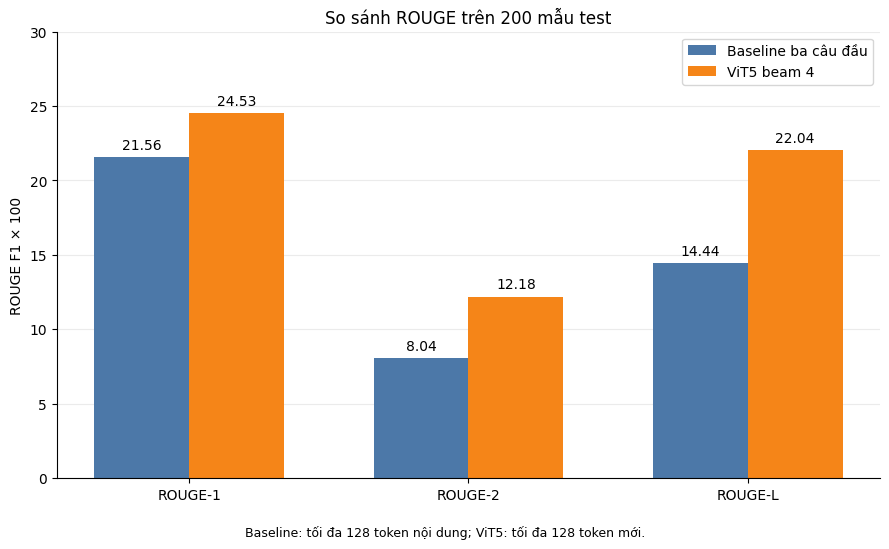

Đã lưu biểu đồ trên Drive: /content/drive/MyDrive/vietnamese-summarization/outputs/test_evaluation_20261108_183331_879067/figures/rouge_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from google.colab import drive, files

drive.mount("/content/drive")

evaluation_id = "test_evaluation_20261108_183331_879067"

evaluation_dir = (
    Path("/content/drive/MyDrive/vietnamese-summarization/outputs")
    / evaluation_id
)

plot_report = json.loads(
    (evaluation_dir / "metrics.json").read_text(encoding="utf-8")
)

if plot_report["evaluation_id"] != evaluation_id:
    raise RuntimeError("Lỗi: Báo cáo không đúng lượt đánh giá.")

for method in ["baseline", "vit5"]:
    if plot_report["results"][method]["sample_count"] != 200:
        raise RuntimeError("Lỗi: Báo cáo không có đủ 200 mẫu.")

metric_names = ["rouge1", "rouge2", "rougeL"]
metric_labels = ["ROUGE-1", "ROUGE-2", "ROUGE-L"]

baseline_values = []
vit5_values = []

for name in metric_names:
    baseline_values.append(
        plot_report["results"]["baseline"]["mean_f1_percent"][name]
    )
    vit5_values.append(
        plot_report["results"]["vit5"]["mean_f1_percent"][name]
    )

positions = [0, 1, 2]
bar_width = 0.34

baseline_positions = []
vit5_positions = []

for position in positions:
    baseline_positions.append(position - bar_width / 2)
    vit5_positions.append(position + bar_width / 2)

fig, ax = plt.subplots(figsize=(9, 5.5))

baseline_bars = ax.bar(
    baseline_positions,
    baseline_values,
    width=bar_width,
    label="Baseline ba câu đầu",
    color="#4C78A8",
)

vit5_bars = ax.bar(
    vit5_positions,
    vit5_values,
    width=bar_width,
    label="ViT5 beam 4",
    color="#F58518",
)

for bars in [baseline_bars, vit5_bars]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.35,
            format(height, ".2f"),
            ha="center",
            va="bottom",
        )

ax.set_title("So sánh ROUGE trên 200 mẫu test")
ax.set_ylabel("ROUGE F1 × 100")
ax.set_xticks(positions)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 30)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper right")

fig.text(
    0.5,
    0.015,
    "Baseline: tối đa 128 token nội dung; ViT5: tối đa 128 token mới.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

figure_dir = evaluation_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "rouge_comparison.png"

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print("Đã lưu biểu đồ trên Drive:", figure_path)

files.download(str(figure_path))